In [ ]:
# !pip uninstall torch-tensorrt tensorrt tensorrt_cu13 tensorrt_cu13_bindings tensorrt_cu13_libs nvidia-tensorrt -y
# !pip install tensorrt==10.6.0 --extra-index-url https://pypi.nvidia.com
# !pip install torch-tensorrt==2.11.0 --extra-index-url https://download.pytorch.org/whl/cu128

[TRT] Building engine on GPU 0 …
[TRT] Engine saved → /app/license-plate-ocr-training/weights/2026-04-28_16-46-51/best_b32_fp16_gpu0.trt


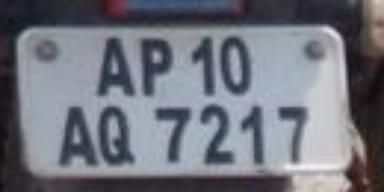

gt: AP10AQ7217
pr: AP10AQ7217


In [1]:
import os
import glob
import numpy as np
from PIL import Image

import pycuda.driver as cuda
import tensorrt as trt

cuda.init()
TRT_LOGGER = trt.Logger(trt.Logger.WARNING)

class LicensePlateOCRTRT:
    ALPHABET = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ_"
    PAD_CHAR  = "_"
    IMG_H     = 64
    IMG_W     = 128

    def __init__(
        self,
        onnx_path: str,
        engine_path: str = None,
        max_batch_size: int = 8,
        force_rebuild: bool = False,
        device_id: int = 0,
    ):
        self.B         = max_batch_size
        self.device_id = device_id

        self._cuda_device  = cuda.Device(device_id)
        self._cuda_context = self._cuda_device.make_context()

        try:
            self._init_engine(onnx_path, engine_path, force_rebuild)
            self._init_buffers()
        except Exception:
            self._cuda_context.pop()
            raise

    def _init_engine(self, onnx_path: str, engine_path: str, force_rebuild: bool):
        onnx_dir = os.path.dirname(os.path.abspath(onnx_path))
        base = os.path.splitext(os.path.basename(onnx_path))[0]
        self.engine_path = engine_path or os.path.join(
            onnx_dir, f"{base}_b{self.B}_fp16_gpu{self.device_id}.trt"
        )

        if force_rebuild or not os.path.exists(self.engine_path):
            self._build_engine(onnx_path)

        runtime = trt.Runtime(TRT_LOGGER)
        with open(self.engine_path, "rb") as f:
            self.engine = runtime.deserialize_cuda_engine(f.read())

        self.context = self.engine.create_execution_context()

        # Resolve I/O tensor names
        self.input_name = self.output_name = None
        for i in range(self.engine.num_io_tensors):
            name = self.engine.get_tensor_name(i)
            mode = self.engine.get_tensor_mode(name)
            if mode == trt.TensorIOMode.INPUT:
                self.input_name = name
            else:
                self.output_name = name

        if self.input_name is None or self.output_name is None:
            raise RuntimeError("Could not resolve TensorRT I/O tensor names.")

        self.max_shape = (self.B, 3, self.IMG_H, self.IMG_W)
        self.context.set_input_shape(self.input_name, self.max_shape)
        self.output_shape = tuple(self.context.get_tensor_shape(self.output_name))

    def _init_buffers(self):
        self.d_input  = cuda.mem_alloc(int(np.prod(self.max_shape))   * 4)
        self.d_output = cuda.mem_alloc(int(np.prod(self.output_shape)) * 4)

        self.h_input  = cuda.pagelocked_empty(self.max_shape,    dtype=np.float32)
        self.h_output = cuda.pagelocked_empty(self.output_shape, dtype=np.float32)

        self.stream = cuda.Stream()

        self.context.set_tensor_address(self.input_name,  int(self.d_input))
        self.context.set_tensor_address(self.output_name, int(self.d_output))

    def _build_engine(self, onnx_path: str):
        builder = trt.Builder(TRT_LOGGER)
        network = builder.create_network(
            1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH)
        )
        parser = trt.OnnxParser(network, TRT_LOGGER)

        with open(onnx_path, "rb") as f:
            if not parser.parse(f.read()):
                errors = "\n".join(
                    str(parser.get_error(i)) for i in range(parser.num_errors)
                )
                raise RuntimeError(f"ONNX parse failed:\n{errors}")

        config = builder.create_builder_config()
        config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 2 << 30)
        config.set_flag(trt.BuilderFlag.FP16)

        profile    = builder.create_optimization_profile()
        input_name = network.get_input(0).name

        profile.set_shape(
            input_name,
            min=(1, 3, self.IMG_H, self.IMG_W),
            opt=(1, 3, self.IMG_H, self.IMG_W),
            max=(self.B, 3, self.IMG_H, self.IMG_W),
        )
        config.add_optimization_profile(profile)

        print(f"[TRT] Building engine on GPU {self.device_id}")
        engine_bytes = builder.build_serialized_network(network, config)
        if engine_bytes is None:
            raise RuntimeError("TensorRT build failed")

        with open(self.engine_path, "wb") as f:
            f.write(engine_bytes)

        print(f"[TRT] Engine saved → {self.engine_path}")

    def _preprocess(self, imgs) -> int:
        if isinstance(imgs, Image.Image):
            imgs = [imgs]

        B = len(imgs)
        if B > self.B:
            raise ValueError(f"Batch size {B} exceeds max_batch_size {self.B}.")

        for i, img in enumerate(imgs):
            img = img.resize((self.IMG_W, self.IMG_H), Image.BILINEAR)
            arr = np.asarray(img, dtype=np.float32)
            self.h_input[i] = arr.transpose(2, 0, 1)

        return B

    def _infer(self, B: int) -> np.ndarray:
        self.context.set_input_shape(self.input_name, (B, 3, self.IMG_H, self.IMG_W))

        cuda.memcpy_htod_async(self.d_input, self.h_input[:B], self.stream)
        self.context.execute_async_v3(self.stream.handle)
        cuda.memcpy_dtoh_async(self.h_output, self.d_output, self.stream)
        self.stream.synchronize()

        return self.h_output[:B]

    def _decode(self, logits: np.ndarray) -> list[str]:
        indices = np.argmax(logits, axis=-1)
        return [
            "".join(self.ALPHABET[i] for i in seq if self.ALPHABET[i] != self.PAD_CHAR)
            for seq in indices
        ]

    def predict(self, imgs) -> list[str]:
        self._cuda_context.push()
        try:
            B      = self._preprocess(imgs)
            logits = self._infer(B)
            return self._decode(logits)
        finally:
            self._cuda_context.pop()

    def __del__(self):
        try:
            self._cuda_context.pop()
        except Exception:
            pass


ONNX_PATH = glob.glob("weights/*/best.onnx")[0]
model = LicensePlateOCRTRT(
    onnx_path=ONNX_PATH,
    max_batch_size=32,
    device_id=0,
)

image_paths = glob.glob("./dataset/lp_crops_balanced/val/*.jpg")

for image_path in image_paths[:5]:
    with open(image_path.replace(".jpg", ".txt")) as f:
        gt = f.read().strip()

    image = Image.open(image_path)
    pred = model.predict(image)[0]

    display(image)
    print("gt:", gt)
    print("pr:", pred)
    break

In [ ]:
from tqdm import tqdm
import Levenshtein

BATCH_SIZE = 32

total = 0
d0 = 0
d1 = 0
d2 = 0

images_path = glob.glob("./dataset/lp_crops_balanced/val/*.jpg")

batch_imgs = []
batch_gts = []

for image_path in tqdm(images_path):
    with open(image_path.replace(".jpg", ".txt")) as f:
        gt = f.read().strip()
        if ("\"" in gt) or (" " in gt):
            continue

    img = Image.open(image_path)
    batch_imgs.append(img)
    batch_gts.append(gt)

    # run batch
    if len(batch_imgs) == BATCH_SIZE:
        preds = model.predict(batch_imgs)

        for gt_i, pred_i in zip(batch_gts, preds):
            dist = Levenshtein.distance(gt_i, pred_i)

            total += 1
            if dist == 0:
                d0 += 1
            if dist <= 1:
                d1 += 1
            if dist <= 2:
                d2 += 1

        batch_imgs.clear()
        batch_gts.clear()

if batch_imgs:
    preds = model.predict(batch_imgs)

    for gt_i, pred_i in zip(batch_gts, preds):
        dist = Levenshtein.distance(gt_i, pred_i)

        total += 1
        if dist == 0:
            d0 += 1
        if dist <= 1:
            d1 += 1
        if dist <= 2:
            d2 += 1

acc_exact = d0 / total
acc_1 = d1 / total
acc_2 = d2 / total

print(f"Exact accuracy (distance=0): {acc_exact:.4f}")
print(f"Accuracy (distance<=1):     {acc_1:.4f}")
print(f"Accuracy (distance<=2):     {acc_2:.4f}")